# Evaluación Regular N°2 - Modelos predictivos

Integrantes: [Completar nombres].
Asignatura: Modelos Predictivos en Negocios.
Fecha de entrega: [Completar fecha].

Este trabajo utiliza el Student Performance Prediction Dataset de Kaggle para estudiar el rendimiento académico y la colocación laboral de estudiantes mediante regresión lineal múltiple y regresión logística.


## 1. Contexto, objetivo e hipótesis

Una institución educativa puede utilizar información de sus estudiantes para estimar su rendimiento académico y orientar programas de apoyo y preparación laboral.

El objetivo general es construir y evaluar una regresión lineal múltiple para estimar el puntaje del examen y una regresión logística para estimar la probabilidad de colocación laboral. Se exploran los datos, se seleccionan variables, se evalúan los modelos y se interpretan sus resultados para discutir posibles aplicaciones en la gestión educativa.

La hipótesis principal plantea que más horas de estudio, mayor asistencia y mejores puntajes previos se relacionan con mejores resultados académicos y mayor probabilidad de colocación laboral.

Como hipótesis exploratoria adicional, se plantea que la relación entre estudiar más y obtener mejores puntajes podría ser distinta entre quienes duermen menos de seis horas y quienes duermen seis horas o más. Esta comparación describe diferencias entre grupos; no demuestra causalidad ni modifica los modelos exigidos.


## 2. Librerías y carga del dataset

Se utiliza pandas para organizar los datos, numpy para cálculos, matplotlib y seaborn para gráficos, scikit-learn para entrenar y evaluar los modelos, y kagglehub para descargar el archivo. El trabajo mantiene un enfoque introductorio y no utiliza statsmodels.

El dataset se seleccionó porque contiene, para los mismos estudiantes, un resultado numérico y un resultado binario, además de variables relacionadas con hábitos y desempeño académico. Esto permite desarrollar las dos tareas solicitadas con un mismo conjunto de datos. Su origen en Kaggle y su orientación educativa no garantizan que represente a otra institución.


In [1]:
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn


In [2]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import precision_score
from sklearn.metrics import r2_score
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

semilla_aleatoria = 42
proporcion_prueba = 0.20


El archivo se descarga desde Kaggle cuando `ruta_csv_local` está vacía. Para utilizar una copia local en Colab, se puede subir el CSV y escribir `/content/student_dataset_10000_rows.csv` en esa variable.

Los nombres originales utilizan minúsculas y guiones bajos. Se normaliza su formato y se renombran `Attendance` como `Attendance Percentage` y `Previous Score` como `Previous Scores` para coincidir con la pauta. Estos cambios afectan únicamente a los nombres, no a los valores.


In [4]:
ruta_csv_local = ""

if ruta_csv_local == "":
    carpeta_dataset = kagglehub.dataset_download(
        "shambhurajejagadale/student-performance-prediction-dataset"
    )
    ruta_dataset = Path(carpeta_dataset) / "student_dataset_10000_rows.csv"
else:
    ruta_dataset = Path(ruta_csv_local)

datos = pd.read_csv(ruta_dataset)
datos.columns = (
    datos.columns.str.strip()
    .str.replace(r"[_\s]+", " ", regex=True)
    .str.title()
)

# La pauta usa dos nombres diferentes a los del CSV.
datos = datos.rename(columns={
    "Attendance": "Attendance Percentage",
    "Previous Score": "Previous Scores",
})

if datos.columns.duplicated().any():
    raise ValueError(
        "Hay nombres de columnas repetidos; revisar el archivo."
    )

variables_predictoras = [
    "Study Hours",
    "Attendance Percentage",
    "Sleep Hours",
    "Internet Usage",
    "Assignments Completed",
    "Previous Scores",
]

variable_objetivo_lineal = "Exam Score"
variable_objetivo_logistica = "Placement Status"

columnas_requeridas = variables_predictoras + [
    variable_objetivo_lineal,
    variable_objetivo_logistica,
]

columnas_faltantes = []
for nombre_columna in columnas_requeridas:
    if nombre_columna not in datos.columns:
        columnas_faltantes.append(nombre_columna)

if len(columnas_faltantes) > 0:
    raise ValueError(
        "Revisar los nombres reales del CSV. Faltan: "
        + str(columnas_faltantes)
        + ". Columnas disponibles: "
        + str(datos.columns.tolist())
    )

print("Filas:", datos.shape[0])
print("Columnas:", datos.shape[1])
display(datos.head())


Using Colab cache for faster access to the 'student-performance-prediction-dataset' dataset.
Filas: 10000
Columnas: 8


,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score,Placement Status
0,7,56,8,7,10,62,100.000,Placed
1,4,69,5,3,8,56,100.000,Placed
2,11,60,7,6,10,45,100.000,Placed
3,8,99,9,8,4,55,90.170,Placed
4,5,52,8,6,8,40,78.820,Placed


## 3. Exploración básica antes de limpiar

Se revisan dimensiones, tipos de datos, faltantes, duplicados y estadísticas descriptivas. Los histogramas de horas de estudio, horas de sueño y puntaje del examen permiten reconocer sus distribuciones y orientar la limpieza.


,Tipo de dato,Valores faltantes,Porcentaje faltante
Study Hours,int64,0,0.000
Attendance Percentage,int64,0,0.000
Sleep Hours,int64,0,0.000
Internet Usage,int64,0,0.000
Assignments Completed,int64,0,0.000
Previous Scores,int64,0,0.000
Exam Score,float64,0,0.000
Placement Status,object,0,0.000


,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,5.990,69.885,6.498,6.063,9.988,64.911,86.704
std,3.164,17.617,1.709,3.138,6.034,17.503,15.058
min,1.000,40.000,4.000,1.000,0.000,35.000,26.670
25%,3.000,55.000,5.000,3.000,5.000,50.000,76.728
50%,6.000,70.000,6.500,6.000,10.000,65.000,92.120
75%,9.000,85.000,8.000,9.000,15.000,80.000,100.000
max,11.000,100.000,9.000,11.000,20.000,95.000,100.000


Filas completamente duplicadas: 0


,count
Placement Status,
Placed,8356
Not Placed,1644


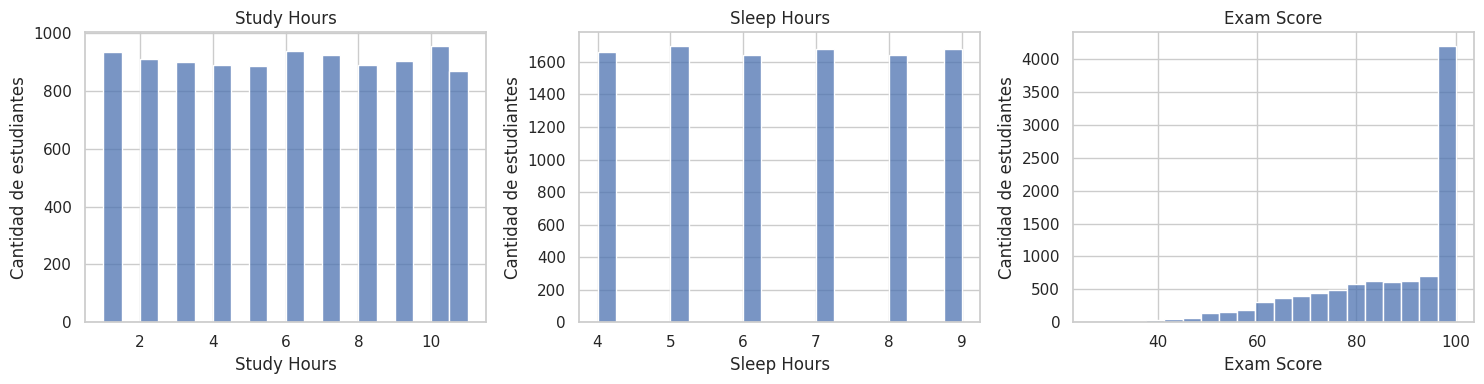

In [5]:
resumen_inicial = pd.DataFrame({
    "Tipo de dato": datos.dtypes.astype(str),
    "Valores faltantes": datos.isna().sum(),
    "Porcentaje faltante": datos.isna().mean() * 100,
})

display(resumen_inicial)
display(datos.describe())
print("Filas completamente duplicadas:", datos.duplicated().sum())
display(datos[variable_objetivo_logistica].value_counts(dropna=False))

variables_graficos = ["Study Hours", "Sleep Hours", "Exam Score"]
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for posicion, nombre_variable in enumerate(variables_graficos):
    valores_numericos = pd.to_numeric(
        datos[nombre_variable],
        errors="coerce",
    )
    sns.histplot(
        valores_numericos.dropna(),
        bins=20,
        ax=ejes[posicion],
    )
    ejes[posicion].set_title(nombre_variable)
    ejes[posicion].set_ylabel("Cantidad de estudiantes")

plt.tight_layout()
plt.show()


El dataset contiene 10.000 estudiantes y ocho variables. No se encontraron valores faltantes ni filas completamente duplicadas. Las horas de estudio presentan un promedio de 5,99 horas diarias y las horas de sueño un promedio de 6,50 horas. La asistencia promedio es de 69,89 %.

Los histogramas muestran frecuencias relativamente parejas entre los valores registrados de estudio y sueño. El puntaje del examen se concentra en valores altos, especialmente en 100 puntos. Su promedio es de 86,70 puntos y su mediana de 92,12 puntos. Esta acumulación será relevante al interpretar el modelo lineal.

En colocación laboral, 8.356 estudiantes aparecen como colocados y 1.644 como no colocados: 83,56 % y 16,44 %, respectivamente. Las clases están desbalanceadas, por lo que una accuracy elevada debe compararse con la estrategia de predecir siempre la clase mayoritaria.


## 4. Limpieza y selección de variables

Se comprueban duplicados exactos, resultados faltantes y valores físicamente imposibles. Los duplicados solo se consideran repetidos si no hay evidencia de que correspondan a personas diferentes. Las filas sin alguno de los resultados se excluirían para mantener una muestra común para ambos modelos.

Se seleccionan como predictores las horas de estudio, asistencia, sueño, uso de internet, tareas completadas y puntajes previos. El puntaje del examen es el objetivo de la regresión lineal y la colocación laboral es el objetivo de la logística, codificada como 1 para colocado y 0 para no colocado.


In [6]:
eliminar_duplicados_exactos = True
filas_iniciales = len(datos)

if eliminar_duplicados_exactos:
    datos_sin_duplicados = datos.drop_duplicates().copy()
else:
    datos_sin_duplicados = datos.copy()

filas_duplicadas_eliminadas = filas_iniciales - len(datos_sin_duplicados)
datos_limpios = datos_sin_duplicados[columnas_requeridas].copy()

columnas_numericas = variables_predictoras + [variable_objetivo_lineal]

for nombre_columna in columnas_numericas:
    datos_limpios[nombre_columna] = pd.to_numeric(
        datos_limpios[nombre_columna],
        errors="coerce",
    )
    datos_limpios[nombre_columna] = datos_limpios[nombre_columna].replace(
        [np.inf, -np.inf],
        np.nan,
    )

estado_laboral_texto = (
    datos_limpios[variable_objetivo_logistica]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[\s_-]+", "", regex=True)
)
estado_laboral_texto = estado_laboral_texto.replace("", pd.NA)

codificacion_estado_laboral = {
    "placed": 1,
    "notplaced": 0,
    "yes": 1,
    "no": 0,
    "1": 1,
    "0": 0,
    "1.0": 1,
    "0.0": 0,
}

categorias_desconocidas = estado_laboral_texto[
    estado_laboral_texto.notna()
    & ~estado_laboral_texto.isin(codificacion_estado_laboral)
].unique()

if len(categorias_desconocidas) > 0:
    raise ValueError(
        "Revisar la codificación de Placement Status: "
        + str(categorias_desconocidas)
    )

datos_limpios[variable_objetivo_logistica] = estado_laboral_texto.map(
    codificacion_estado_laboral
)

limites_fisicos = {
    "Study Hours": (0, 24),
    "Attendance Percentage": (0, 100),
    "Sleep Hours": (0, 24),
    "Internet Usage": (0, 24),
}

valores_invalidos = []

for nombre_variable, limites in limites_fisicos.items():
    limite_inferior = limites[0]
    limite_superior = limites[1]
    mascara_invalida = (
        (datos_limpios[nombre_variable] < limite_inferior)
        | (datos_limpios[nombre_variable] > limite_superior)
    )
    valores_invalidos.append({
        "Variable": nombre_variable,
        "Valores fuera del rango físico": int(mascara_invalida.sum()),
    })
    datos_limpios.loc[mascara_invalida, nombre_variable] = np.nan

mascara_tareas_invalidas = datos_limpios["Assignments Completed"] < 0
valores_invalidos.append({
    "Variable": "Assignments Completed",
    "Valores fuera del rango físico": int(mascara_tareas_invalidas.sum()),
})
datos_limpios.loc[mascara_tareas_invalidas, "Assignments Completed"] = np.nan

filas_antes_de_revisar_objetivos = len(datos_limpios)
datos_limpios = datos_limpios.dropna(
    subset=[variable_objetivo_lineal, variable_objetivo_logistica]
).copy()
datos_limpios[variable_objetivo_logistica] = (
    datos_limpios[variable_objetivo_logistica].astype(int)
)

filas_sin_objetivo_eliminadas = (
    filas_antes_de_revisar_objetivos - len(datos_limpios)
)

print("Duplicados eliminados:", filas_duplicadas_eliminadas)
print("Filas sin resultados eliminadas:", filas_sin_objetivo_eliminadas)
print("Filas disponibles:", len(datos_limpios))
display(pd.DataFrame(valores_invalidos))
display(datos_limpios[columnas_requeridas].isna().sum().to_frame("Faltantes"))


Duplicados eliminados: 0
Filas sin resultados eliminadas: 0
Filas disponibles: 10000


,Variable,Valores fuera del rango físico
0,Study Hours,0
1,Attendance Percentage,0
2,Sleep Hours,0
3,Internet Usage,0
4,Assignments Completed,0


,Faltantes
Study Hours,0
Attendance Percentage,0
Sleep Hours,0
Internet Usage,0
Assignments Completed,0
Previous Scores,0
Exam Score,0
Placement Status,0


La revisión no identificó duplicados, resultados faltantes ni valores fuera de los rangos físicos definidos. No fue necesario eliminar observaciones y se conservaron los 10.000 registros.

Se revisaron horas diarias entre 0 y 24, asistencia entre 0 y 100 % y tareas no negativas. No se impuso una escala de puntajes sin confirmar su definición. Todas las variables predictoras seleccionadas presentaron variación suficiente en entrenamiento.

El código prepara una imputación con medianas de entrenamiento para posibles faltantes en predictores, pero no tuvo que reemplazar valores en esta ejecución. El puntaje del examen se excluyó de los predictores laborales para representar una predicción realizada antes del examen final.


## 5. Valores atípicos

El rango intercuartílico o IQR permite señalar observaciones poco frecuentes. Se calculan límites de 1,5 veces el IQR por debajo del primer cuartil y por encima del tercer cuartil. Un valor fuera de estos límites no constituye necesariamente un error.


,Variable,Límite inferior IQR,Límite superior IQR,Cantidad señalada
0,Study Hours,-6.000,18.000,0
1,Attendance Percentage,10.000,130.000,0
2,Sleep Hours,0.500,12.500,0
3,Internet Usage,-6.000,18.000,0
4,Assignments Completed,-10.000,30.000,0
5,Previous Scores,5.000,125.000,0
6,Exam Score,41.819,134.909,62


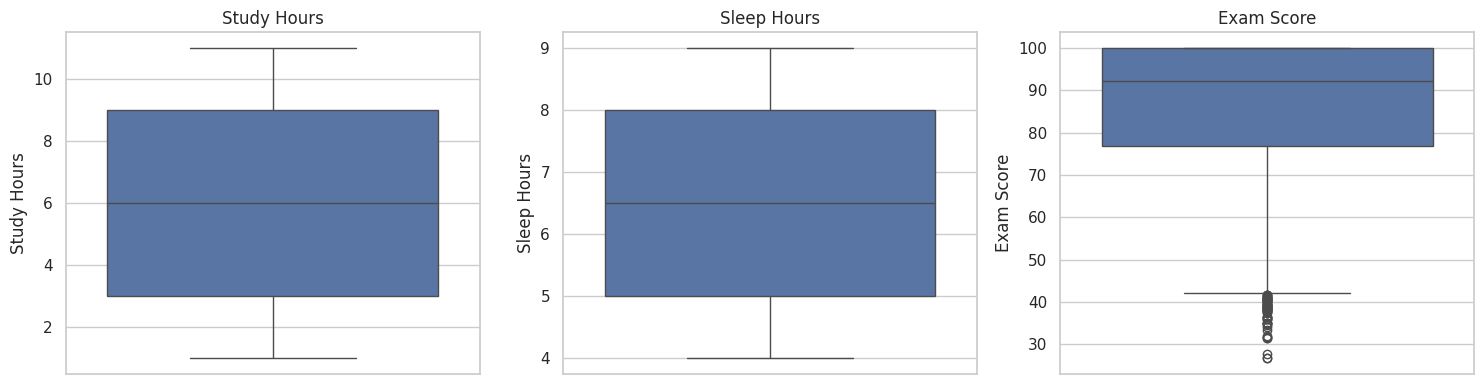

In [7]:
resumen_atipicos = []

for nombre_variable in columnas_numericas:
    valores = datos_limpios[nombre_variable].dropna()
    primer_cuartil = valores.quantile(0.25)
    tercer_cuartil = valores.quantile(0.75)
    rango_intercuartilico = tercer_cuartil - primer_cuartil

    limite_inferior = primer_cuartil - 1.5 * rango_intercuartilico
    limite_superior = tercer_cuartil + 1.5 * rango_intercuartilico

    cantidad_atipicos = (
        (valores < limite_inferior)
        | (valores > limite_superior)
    ).sum()

    resumen_atipicos.append({
        "Variable": nombre_variable,
        "Límite inferior IQR": limite_inferior,
        "Límite superior IQR": limite_superior,
        "Cantidad señalada": int(cantidad_atipicos),
    })

display(pd.DataFrame(resumen_atipicos))

figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for posicion, nombre_variable in enumerate(variables_graficos):
    sns.boxplot(
        y=datos_limpios[nombre_variable],
        ax=ejes[posicion],
    )
    ejes[posicion].set_title(nombre_variable)

plt.tight_layout()
plt.show()


El método no señaló valores atípicos en las seis variables predictoras. En el puntaje del examen identificó 62 observaciones por debajo de aproximadamente 41,82 puntos, equivalentes al 0,62 % del dataset.

Estas observaciones se conservaron porque un puntaje bajo es posible y no representa por sí mismo un error. Eliminarlas reduciría la representación de estudiantes con bajo rendimiento, precisamente relevantes para orientar apoyos académicos.

El diagrama de caja del examen también muestra una concentración de puntajes altos y una cola hacia resultados bajos. Esto ayuda a explicar por qué el criterio IQR señala algunos puntajes bajos.


## 6. División de entrenamiento y prueba

Se utiliza el 80 % de los estudiantes para entrenamiento y el 20 % para prueba, con `random_state=42`. La división estratificada conserva aproximadamente la proporción de colocados y no colocados en ambos grupos. Ambos modelos utilizan los mismos estudiantes de entrenamiento y prueba.

Las medianas, la revisión de variables constantes y la estandarización se ajustan únicamente con entrenamiento, evitando utilizar información de prueba en la preparación de los modelos.


In [8]:
conteo_clases = datos_limpios[variable_objetivo_logistica].value_counts()

if len(conteo_clases) != 2 or conteo_clases.min() < 2:
    raise ValueError(
        "Se necesitan las dos clases laborales y suficientes observaciones "
        "para realizar una división estratificada."
    )

datos_entrenamiento, datos_prueba = train_test_split(
    datos_limpios,
    test_size=proporcion_prueba,
    random_state=semilla_aleatoria,
    stratify=datos_limpios[variable_objetivo_logistica],
)

print("Estudiantes en entrenamiento:", len(datos_entrenamiento))
print("Estudiantes en prueba:", len(datos_prueba))

proporciones_clases = pd.DataFrame({
    "Entrenamiento": datos_entrenamiento[variable_objetivo_logistica]
        .value_counts(normalize=True),
    "Prueba": datos_prueba[variable_objetivo_logistica]
        .value_counts(normalize=True),
})
display(proporciones_clases)

variables_utilizadas = variables_predictoras.copy()
variables_excluidas = []

for nombre_variable in variables_predictoras:
    cantidad_valores_distintos = datos_entrenamiento[nombre_variable].nunique()
    if cantidad_valores_distintos <= 1:
        variables_utilizadas.remove(nombre_variable)
        variables_excluidas.append(nombre_variable)

if len(variables_utilizadas) == 0:
    raise ValueError("No quedan predictores con variación para entrenar.")

print("Predictores utilizados:", variables_utilizadas)
print("Predictores sin variación suficiente:", variables_excluidas)

predictores_entrenamiento = datos_entrenamiento[variables_utilizadas]
predictores_prueba = datos_prueba[variables_utilizadas]

puntaje_entrenamiento = datos_entrenamiento[variable_objetivo_lineal]
puntaje_prueba = datos_prueba[variable_objetivo_lineal]

colocacion_entrenamiento = datos_entrenamiento[variable_objetivo_logistica]
colocacion_prueba = datos_prueba[variable_objetivo_logistica]

imputador = SimpleImputer(strategy="median")
predictores_entrenamiento_completos = imputador.fit_transform(
    predictores_entrenamiento
)
predictores_prueba_completos = imputador.transform(predictores_prueba)

tabla_medianas = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Mediana de entrenamiento": imputador.statistics_,
})
display(tabla_medianas)

estandarizador = StandardScaler()
predictores_entrenamiento_estandarizados = estandarizador.fit_transform(
    predictores_entrenamiento_completos
)
predictores_prueba_estandarizados = estandarizador.transform(
    predictores_prueba_completos
)


Estudiantes en entrenamiento: 8000
Estudiantes en prueba: 2000


,Entrenamiento,Prueba
Placement Status,,
1,0.836,0.836
0,0.164,0.165


Predictores utilizados: ['Study Hours', 'Attendance Percentage', 'Sleep Hours', 'Internet Usage', 'Assignments Completed', 'Previous Scores']
Predictores sin variación suficiente: []


,Variable,Mediana de entrenamiento
0,Study Hours,6.000
1,Attendance Percentage,70.000
2,Sleep Hours,7.000
3,Internet Usage,6.000
4,Assignments Completed,10.000
5,Previous Scores,65.000


La división produjo 8.000 estudiantes de entrenamiento y 2.000 de prueba. En ambos conjuntos, aproximadamente el 83,6 % corresponde a colocados. Ninguna variable predictora fue excluida por falta de variación.

La regresión lineal utiliza unidades originales para facilitar la interpretación de sus coeficientes. La logística utiliza variables estandarizadas para facilitar el ajuste numérico. Estandarizar resta el promedio y divide por la desviación estándar de entrenamiento: conserva la información y las correlaciones entre variables no constantes, pero cambia las unidades y el punto cero.

Las predicciones se evalúan con estudiantes no utilizados para ajustar los modelos. Esto permite estudiar su desempeño en casos nuevos del mismo dataset, sin demostrar todavía que se mantendrá en otra institución o período.


## 7. Hipótesis adicional y relaciones básicas

Se utiliza únicamente entrenamiento para comparar grupos y explorar relaciones. Se considera estudio alto estudiar seis horas o más, según la mediana de entrenamiento, y sueño corto dormir menos de seis horas diarias. El límite de estudio es relativo a esta muestra y no una recomendación académica.

Se muestran cantidades, promedios y desviaciones estándar para interpretar las diferencias considerando el tamaño y la dispersión de cada grupo.


Mediana de horas de estudio: 6.0
Estudiantes utilizados en la comparación: 8000


Cantidad de estudiantes  \
Grupo de sueño   Grupo de estudio                                         
6 horas o más    Igual o superior a la mediana                     2905   
                 Inferior a la mediana                             2427   
Menos de 6 horas Igual o superior a la mediana                     1466   
                 Inferior a la mediana                             1202   

                                                Puntaje promedio  \
Grupo de sueño   Grupo de estudio                                  
6 horas o más    Igual o superior a la mediana            94.576   
                 Inferior a la mediana                    80.180   
Menos de 6 horas Igual o superior a la mediana            91.811   
                 Inferior a la mediana                    74.884   

                                                Desviación estándar  
Grupo de sueño   Grupo de estudio                                    
6 horas o más    Igual o superior a la mediana                9.191  
                 Inferior a la mediana                       15.467  
Menos de 6 horas Igual o superior a la mediana               11.299  
                 Inferior a la mediana                       16.304

,Study Hours,Attendance Percentage,Sleep Hours,Internet Usage,Assignments Completed,Previous Scores,Exam Score
Study Hours,1.000,0.002,-0.002,-0.003,-0.006,0.003,0.560
Attendance Percentage,0.002,1.000,-0.002,-0.011,-0.017,-0.004,0.216
Sleep Hours,-0.002,-0.002,1.000,0.006,-0.001,0.026,0.146
Internet Usage,-0.003,-0.011,0.006,1.000,0.016,-0.001,-0.156
Assignments Completed,-0.006,-0.017,-0.001,0.016,1.000,0.015,0.398
Previous Scores,0.003,-0.004,0.026,-0.001,0.015,1.000,0.317
Exam Score,0.560,0.216,0.146,-0.156,0.398,0.317,1.000


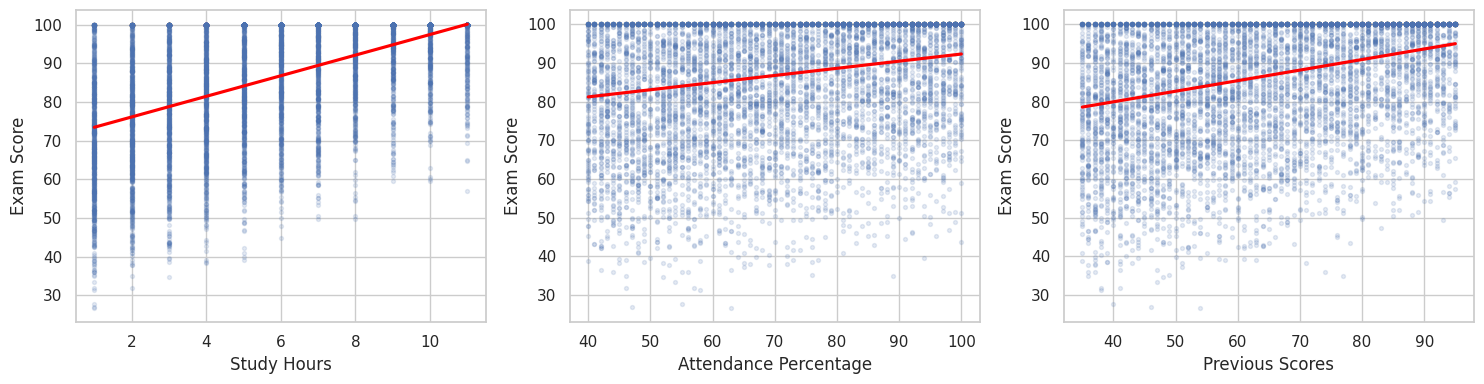

In [9]:
datos_hipotesis = datos_entrenamiento.dropna(
    subset=["Study Hours", "Sleep Hours"]
).copy()

if len(datos_hipotesis) == 0:
    print(
        "No hay datos completos de estudio y sueño para esta comparación."
    )
else:
    mediana_horas_estudio = datos_entrenamiento["Study Hours"].median()

    datos_hipotesis["Grupo de estudio"] = np.where(
        datos_hipotesis["Study Hours"] >= mediana_horas_estudio,
        "Igual o superior a la mediana",
        "Inferior a la mediana",
    )
    datos_hipotesis["Grupo de sueño"] = np.where(
        datos_hipotesis["Sleep Hours"] < 6,
        "Menos de 6 horas",
        "6 horas o más",
    )

    comparacion_hipotesis = (
        datos_hipotesis
        .groupby(["Grupo de sueño", "Grupo de estudio"])["Exam Score"]
        .agg(["count", "mean", "std"])
        .rename(columns={
            "count": "Cantidad de estudiantes",
            "mean": "Puntaje promedio",
            "std": "Desviación estándar",
        })
    )

    print("Mediana de horas de estudio:", mediana_horas_estudio)
    print("Estudiantes utilizados en la comparación:", len(datos_hipotesis))
    display(comparacion_hipotesis)

correlaciones_entrenamiento = datos_entrenamiento[
    columnas_numericas
].corr()
display(correlaciones_entrenamiento)

figura, ejes = plt.subplots(1, 3, figsize=(15, 4))
variables_relacion_puntaje = [
    "Study Hours",
    "Attendance Percentage",
    "Previous Scores",
]

for posicion, nombre_variable in enumerate(variables_relacion_puntaje):
    sns.regplot(
        data=datos_entrenamiento,
        x=nombre_variable,
        y="Exam Score",
        ci=None,
        scatter_kws={"alpha": 0.15, "s": 8},
        line_kws={"color": "red"},
        ax=ejes[posicion],
    )

plt.tight_layout()
plt.show()


Entre quienes dormían seis horas o más, los 2.905 estudiantes con estudio alto obtuvieron un promedio de 94,58 puntos, frente a 80,18 puntos de los 2.427 con estudio bajo: una diferencia de 14,40 puntos.

Entre quienes dormían menos de seis horas, los 1.466 estudiantes con estudio alto obtuvieron 91,81 puntos en promedio, frente a 74,88 de los 1.202 con estudio bajo: una diferencia de 16,93 puntos.

Estudiar más se asoció con mejores promedios en ambos grupos de sueño. No se observó que esa ventaja desapareciera al dormir poco; descriptivamente, la diferencia fue incluso mayor en ese grupo. Dentro de cada nivel de estudio, quienes dormían seis horas o más presentaron mejores promedios.

Esta comparación no controla otras diferencias entre estudiantes ni incluye una prueba formal de interacción. Por eso no demuestra que estudiar o dormir más cause un mejor resultado. Las desviaciones estándar también muestran variación relevante dentro de los grupos.

Las horas de estudio presentan la correlación positiva más marcada con el examen, con 0,560, seguidas por tareas completadas, con 0,398, y puntajes previos, con 0,317. El uso de internet presenta una correlación negativa de −0,156. Las correlaciones entre predictores son cercanas a cero, sin relaciones lineales fuertes entre ellos en esta muestra.


## 8. Regresión lineal múltiple

La regresión lineal estima el puntaje del examen utilizando los seis predictores. Sus coeficientes indican el cambio estimado de puntaje al aumentar una unidad de cada variable, manteniendo constantes las demás. Una unidad de asistencia corresponde a un punto porcentual.

Se evalúan MAE, RMSE y R² en prueba y se comparan con una referencia que siempre predice el promedio de entrenamiento.


In [10]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(
    predictores_entrenamiento_completos,
    puntaje_entrenamiento,
)

puntajes_predichos = modelo_lineal.predict(predictores_prueba_completos)

coeficientes_lineales = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Cambio de puntaje por una unidad": modelo_lineal.coef_,
})

print("Intercepto del modelo lineal:", modelo_lineal.intercept_)
display(coeficientes_lineales)

error_absoluto_medio = mean_absolute_error(
    puntaje_prueba,
    puntajes_predichos,
)
raiz_error_cuadratico_medio = np.sqrt(
    mean_squared_error(puntaje_prueba, puntajes_predichos)
)
coeficiente_determinacion = r2_score(
    puntaje_prueba,
    puntajes_predichos,
)

modelo_referencia_lineal = DummyRegressor(strategy="mean")
modelo_referencia_lineal.fit(
    predictores_entrenamiento_completos,
    puntaje_entrenamiento,
)
puntajes_referencia = modelo_referencia_lineal.predict(
    predictores_prueba_completos
)

metricas_lineales = pd.DataFrame({
    "Modelo": ["Regresión lineal", "Promedio de entrenamiento"],
    "MAE": [
        error_absoluto_medio,
        mean_absolute_error(puntaje_prueba, puntajes_referencia),
    ],
    "RMSE": [
        raiz_error_cuadratico_medio,
        np.sqrt(mean_squared_error(puntaje_prueba, puntajes_referencia)),
    ],
    "R cuadrado": [
        coeficiente_determinacion,
        r2_score(puntaje_prueba, puntajes_referencia),
    ],
})

display(metricas_lineales)


Intercepto del modelo lineal: 26.920012980668723


,Variable,Cambio de puntaje por una unidad
0,Study Hours,2.671
1,Attendance Percentage,0.189
2,Sleep Hours,1.244
3,Internet Usage,-0.765
4,Assignments Completed,1.004
5,Previous Scores,0.264


,Modelo,MAE,RMSE,R cuadrado
0,Regresión lineal,6.917,8.791,0.653
1,Promedio de entrenamiento,12.546,14.932,-0.000


Los coeficientes indican asociaciones positivas para estudio, asistencia, sueño, tareas y puntajes previos, y una asociación negativa para uso de internet. Una hora adicional de estudio se asocia con 2,671 puntos más; una tarea adicional, con 1,004 puntos más; y una hora adicional de internet, con 0,765 puntos menos, manteniendo constantes las otras variables. Son asociaciones estimadas y no efectos causales garantizados.

El **MAE fue de 6,917 puntos**, frente a 12,546 de la referencia. El error absoluto promedio se redujo aproximadamente un 45 %. En gestión educativa, esta magnitud ayuda a valorar si la estimación es suficientemente precisa para orientar tutorías.

El **RMSE fue de 8,791 puntos**, frente a 14,932 de la referencia. Esta métrica da más peso a errores grandes. Su diferencia con el MAE muestra que algunos errores elevados tienen un peso relevante en la evaluación.

El **R² fue de 0,653**: el modelo explica aproximadamente el 65,3 % de la variación observada de los puntajes en prueba. No equivale al porcentaje de estudiantes cuyo puntaje se predijo exactamente. La referencia obtuvo un R² prácticamente cero, ligeramente negativo por utilizar el promedio de entrenamiento en prueba.

El modelo mejora frente a predecir el promedio, pero su error obliga a utilizar información adicional antes de tomar decisiones individuales. El intercepto de 26,92 no tiene una interpretación práctica directa, porque el caso con todos los predictores en cero queda fuera de los rangos observados de varias variables.


## 9. Regresión logística

La regresión logística estima la probabilidad de colocación laboral. Se clasifica como colocado cuando la probabilidad es igual o superior a 0,50. Se utiliza la configuración habitual de scikit-learn, con regularización L2 y sin ajustar hiperparámetros mediante el conjunto de prueba.

Se analizan accuracy, precision y recall, tomando colocado como clase positiva. La matriz de confusión permite interpretar los errores según su consecuencia práctica. Los coeficientes se convierten a unidades originales para calcular odds ratios por hora, tarea, punto o punto porcentual.


,Variable,Coeficiente en unidades originales,Odds ratio por una unidad
0,Study Hours,0.728,2.072
1,Attendance Percentage,0.058,1.060
2,Sleep Hours,0.365,1.440
3,Internet Usage,-0.215,0.807
4,Assignments Completed,0.272,1.313
5,Previous Scores,0.070,1.073


,Modelo,Accuracy,Precision,Recall
0,Regresión logística,0.906,0.931,0.959
1,Clase más frecuente,0.836,0.836,1.000


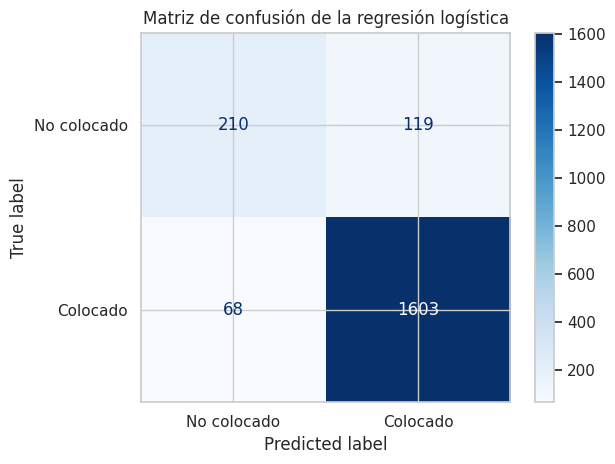

In [11]:
modelo_logistico = LogisticRegression(
    max_iter=2000,
    random_state=semilla_aleatoria,
)
modelo_logistico.fit(
    predictores_entrenamiento_estandarizados,
    colocacion_entrenamiento,
)

probabilidades_colocacion = modelo_logistico.predict_proba(
    predictores_prueba_estandarizados
)[:, 1]

umbral_clasificacion = 0.50
colocaciones_predichas = (
    probabilidades_colocacion >= umbral_clasificacion
).astype(int)

coeficientes_logisticos_originales = (
    modelo_logistico.coef_[0] / estandarizador.scale_
)

coeficientes_logisticos = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Coeficiente en unidades originales": coeficientes_logisticos_originales,
    "Odds ratio por una unidad": np.exp(coeficientes_logisticos_originales),
})
display(coeficientes_logisticos)

exactitud = accuracy_score(colocacion_prueba, colocaciones_predichas)
precision = precision_score(
    colocacion_prueba,
    colocaciones_predichas,
    zero_division=0,
)
sensibilidad = recall_score(
    colocacion_prueba,
    colocaciones_predichas,
    zero_division=0,
)

modelo_referencia_logistico = DummyClassifier(strategy="most_frequent")
modelo_referencia_logistico.fit(
    predictores_entrenamiento_estandarizados,
    colocacion_entrenamiento,
)
colocaciones_referencia = modelo_referencia_logistico.predict(
    predictores_prueba_estandarizados
)

metricas_logisticas = pd.DataFrame({
    "Modelo": ["Regresión logística", "Clase más frecuente"],
    "Accuracy": [
        exactitud,
        accuracy_score(colocacion_prueba, colocaciones_referencia),
    ],
    "Precision": [
        precision,
        precision_score(
            colocacion_prueba,
            colocaciones_referencia,
            zero_division=0,
        ),
    ],
    "Recall": [
        sensibilidad,
        recall_score(
            colocacion_prueba,
            colocaciones_referencia,
            zero_division=0,
        ),
    ],
})

display(metricas_logisticas)

ConfusionMatrixDisplay.from_predictions(
    colocacion_prueba,
    colocaciones_predichas,
    labels=[0, 1],
    display_labels=["No colocado", "Colocado"],
    cmap="Blues",
    values_format="d",
)
plt.title("Matriz de confusión de la regresión logística")
plt.tight_layout()
plt.show()


Una hora adicional de estudio presenta un odds ratio de 2,072: las odds de colocación son aproximadamente el doble, manteniendo constantes las otras variables. Una tarea adicional presenta un odds ratio de 1,313 y una hora adicional de uso de internet uno de 0,807, correspondientes a aproximadamente 31,3 % más y 19,3 % menos odds, respectivamente.

Las odds son la probabilidad dividida por uno menos la probabilidad. Un aumento en las odds no equivale al mismo aumento porcentual o en puntos porcentuales de probabilidad. Estos resultados describen asociaciones estimadas, sin demostrar causalidad.

Los porcentajes siguientes se calculan con los conteos de la matriz de confusión, evitando la pérdida de precisión por redondeo de la tabla:

- **Accuracy: 90,65 %.** Se clasificaron correctamente 1.813 de 2.000 estudiantes. La referencia obtuvo 83,55 %, por lo que la mejora fue de 7,10 puntos porcentuales.
- **Precision: 93,09 %.** De los 1.722 estudiantes clasificados como colocados, 1.603 realmente lo estaban. Una precisión menor produciría más expectativas favorables incorrectas.
- **Recall: 95,93 %.** Se identificó a 1.603 de los 1.671 estudiantes realmente colocados. Esta métrica corresponde a colocados, no a la detección de estudiantes en riesgo de no colocarse.

La matriz registra 210 no colocados correctamente identificados, 119 no colocados clasificados como colocados, 68 colocados clasificados como no colocados y 1.603 colocados correctamente identificados.

Si la institución quiere apoyar a estudiantes con dificultades de colocación, los 119 casos no colocados clasificados como colocados son especialmente relevantes: podrían quedar fuera de una intervención por una expectativa demasiado favorable. Los 68 errores en sentido contrario podrían generar apoyos innecesarios.

La referencia obtiene recall de 100 % para colocados porque clasifica a todos como colocados, pero no identifica a ningún no colocado. Por ello, ese valor aislado no implica un modelo más útil. Las probabilidades estimadas tampoco son garantías de colocación ni intervalos de confianza.


## 10. Revisión de supuestos y variables relevantes

Los gráficos de relaciones y residuos permiten revisar si una relación lineal sencilla representa adecuadamente los datos. El residuo se calcula como puntaje observado menos puntaje estimado. Un patrón marcado o una dispersión que cambia merece discusión.

Para comparar magnitudes dentro de cada modelo, se expresan los efectos por una desviación estándar. Así se evita comparar directamente coeficientes de variables que tienen unidades diferentes, como horas y porcentajes.


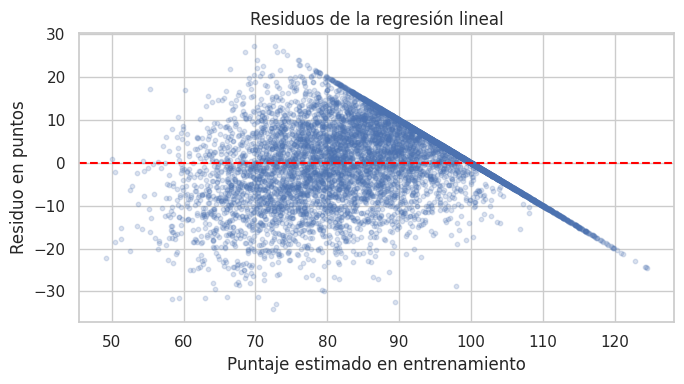

Orden descriptivo de efectos dentro de la regresión lineal:


,Variable,Cambio de puntaje por una desviación estándar,Coeficiente logístico por una desviación estándar,Magnitud del efecto lineal,Magnitud del efecto logístico
0,Study Hours,8.454,2.305,8.454,2.305
4,Assignments Completed,6.081,1.648,6.081,1.648
5,Previous Scores,4.627,1.235,4.627,1.235
1,Attendance Percentage,3.341,1.028,3.341,1.028
3,Internet Usage,-2.392,-0.671,2.392,0.671
2,Sleep Hours,2.123,0.622,2.123,0.622


Orden descriptivo de efectos dentro de la regresión logística:


,Variable,Cambio de puntaje por una desviación estándar,Coeficiente logístico por una desviación estándar,Magnitud del efecto lineal,Magnitud del efecto logístico
0,Study Hours,8.454,2.305,8.454,2.305
4,Assignments Completed,6.081,1.648,6.081,1.648
5,Previous Scores,4.627,1.235,4.627,1.235
1,Attendance Percentage,3.341,1.028,3.341,1.028
3,Internet Usage,-2.392,-0.671,2.392,0.671
2,Sleep Hours,2.123,0.622,2.123,0.622


In [12]:
puntajes_ajustados_entrenamiento = modelo_lineal.predict(
    predictores_entrenamiento_completos
)
residuos_entrenamiento = (
    puntaje_entrenamiento.to_numpy() - puntajes_ajustados_entrenamiento
)

plt.figure(figsize=(7, 4))
plt.scatter(
    puntajes_ajustados_entrenamiento,
    residuos_entrenamiento,
    alpha=0.20,
    s=10,
)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Puntaje estimado en entrenamiento")
plt.ylabel("Residuo en puntos")
plt.title("Residuos de la regresión lineal")
plt.tight_layout()
plt.show()

efectos_lineales_comparables = (
    modelo_lineal.coef_ * estandarizador.scale_
)

comparacion_variables = pd.DataFrame({
    "Variable": variables_utilizadas,
    "Cambio de puntaje por una desviación estándar": efectos_lineales_comparables,
    "Coeficiente logístico por una desviación estándar": modelo_logistico.coef_[0],
})

comparacion_variables["Magnitud del efecto lineal"] = np.abs(
    comparacion_variables["Cambio de puntaje por una desviación estándar"]
)
comparacion_variables["Magnitud del efecto logístico"] = np.abs(
    comparacion_variables["Coeficiente logístico por una desviación estándar"]
)

print("Orden descriptivo de efectos dentro de la regresión lineal:")
display(
    comparacion_variables.sort_values(
        "Magnitud del efecto lineal",
        ascending=False,
    )
)

print("Orden descriptivo de efectos dentro de la regresión logística:")
display(
    comparacion_variables.sort_values(
        "Magnitud del efecto logístico",
        ascending=False,
    )
)


Los gráficos muestran relaciones positivas del examen con estudio, asistencia y puntajes previos, pero también una concentración de resultados en 100 puntos. El gráfico de residuos presenta un patrón descendente en las predicciones altas y una dispersión que no es uniforme.

Cuando el resultado observado es 100, el residuo corresponde a 100 menos el puntaje estimado, formando la diagonal visible. Además, hay estimaciones de entrenamiento superiores a 100. Esto muestra un efecto techo y una limitación de la regresión lineal para representar puntajes altos. No corresponde afirmar que todos los supuestos se cumplen.

La independencia no se puede confirmar solo mediante estos gráficos o la ausencia de duplicados: se necesita conocer la construcción del dataset. La logística supone una relación lineal entre los predictores continuos y el logaritmo de las odds, supuesto que no se verificó formalmente en este análisis introductorio.

Ambos modelos presentan el mismo orden descriptivo de magnitudes: horas de estudio, tareas completadas, puntajes previos, asistencia, uso de internet y sueño. En el modelo lineal, una desviación estándar adicional de estudio se asocia con 8,454 puntos más, frente a 6,081 de tareas y 4,627 de puntajes previos.

Los signos positivos de estudio, asistencia y puntajes previos respaldan descriptivamente la hipótesis principal. El uso de internet muestra asociación negativa en ambos modelos. El orden de coeficientes no demuestra importancia causal ni significancia estadística, y no se comparan numéricamente los efectos lineales con los logísticos porque tienen unidades distintas.


## 11. Predicciones para estudiantes no utilizados en entrenamiento

Se muestran diez casos de prueba con resultados observados, predicciones y probabilidades. La fila original identifica el registro y no se utiliza como predictor. Estos ejemplos complementan la evaluación completa de los 2.000 casos de prueba.


In [13]:
resultados_prueba = pd.DataFrame({
    "Fila original": datos_prueba.index,
    "Puntaje real": puntaje_prueba.to_numpy(),
    "Puntaje estimado": puntajes_predichos,
    "Colocación real": colocacion_prueba.to_numpy(),
    "Colocación estimada": colocaciones_predichas,
    "Probabilidad de colocación": probabilidades_colocacion,
})

resultados_prueba["Error absoluto del puntaje"] = np.abs(
    resultados_prueba["Puntaje real"] - resultados_prueba["Puntaje estimado"]
)

display(resultados_prueba.head(10))


,Fila original,Puntaje real,Puntaje estimado,Colocación real,Colocación estimada,Probabilidad de colocación,Error absoluto del puntaje
0,4768,100.000,74.997,1,1,0.641,25.003
1,1131,85.510,86.295,1,1,0.975,0.785
2,6125,75.800,89.351,1,1,0.991,13.551
3,2781,52.320,62.870,0,0,0.056,10.550
4,17,91.890,83.823,1,1,0.959,8.067
5,2290,100.000,96.881,1,1,0.999,3.119
6,1879,100.000,89.393,1,1,0.992,10.607
7,935,87.850,82.324,1,1,0.943,5.526
8,13,100.000,92.304,1,1,0.996,7.696
9,9082,94.030,99.963,1,1,0.999,5.933


En el registro 1131, el puntaje observado fue de 85,51 y el estimado de 86,30, con un error de aproximadamente 0,79 puntos. En el registro 4768, el resultado fue de 100 y la estimación de 75,00, con un error cercano a 25 puntos. El error puede variar considerablemente entre estudiantes.

En este último registro, el modelo laboral clasificó correctamente al estudiante como colocado, con probabilidad estimada de 64,1 %. Acertar la clasificación laboral no implica estimar correctamente el puntaje académico, porque son tareas diferentes.

La institución podría usar las estimaciones como señales para orientar tutorías y preparación laboral, complementándolas con información adicional y revisión humana. Estos casos no demuestran que el desempeño se mantendrá en otra institución o que los modelos anticipen tendencias de años futuros.


## 12. Comparación, discusión y conclusiones

Ambos modelos mejoraron frente a sus respectivas referencias. La regresión lineal redujo el MAE de 12,546 a 6,917 puntos y obtuvo RMSE de 8,791 y R² de 0,653. La logística alcanzó accuracy de 90,65 %, precision de 93,09 % y recall de 95,93 %, superando la accuracy de 83,55 % de predecir siempre colocado.

No corresponde comparar directamente R² con accuracy porque evalúan tareas diferentes. La comparación relevante es cuánto aporta cada modelo frente a su referencia y qué utilidad tienen sus resultados para la institución.

La hipótesis principal recibió apoyo descriptivo: estudio, asistencia y puntajes previos mostraron asociaciones positivas en ambos modelos. Las tareas completadas también destacaron, con el segundo mayor efecto estandarizado en ambas tareas.

La hipótesis adicional mostró que estudiar más se relacionó con mejores promedios en ambos grupos de sueño. La diferencia entre estudio alto y bajo fue de 14,40 puntos al dormir seis horas o más y de 16,93 puntos al dormir menos de seis horas. A su vez, dormir seis horas o más se asoció con mejores promedios dentro de cada grupo de estudio. Esto no confirma una interacción estadística ni una relación causal.

Los tres hallazgos principales fueron:

1. **Estudio y tareas completadas destacaron en ambos modelos.** Son variables relevantes para observar y discutir al diseñar apoyos educativos, sin interpretar sus coeficientes como efectos causales.
2. **La regresión lineal mejoró frente al promedio.** Sin embargo, mantuvo errores importantes en algunos casos y dificultades asociadas a la concentración de puntajes en 100.
3. **La logística mejoró la clasificación laboral.** Aun así, clasificó como colocados a 119 estudiantes que no lo estaban, un error relevante al priorizar apoyos.

Como aplicación, la institución podría utilizar estas estimaciones para orientar una revisión más detallada de estudiantes que requieren tutorías o preparación laboral. Antes de asignar recursos, debe considerar los errores, información adicional y revisión humana.

Las principales limitaciones son el origen y representatividad no confirmados del dataset, la independencia no verificada, el efecto techo de los puntajes y la falta de evaluación en otra institución o período. No se verificó formalmente la linealidad del logaritmo de las odds ni se comprobó si las probabilidades estimadas coinciden con las frecuencias reales mediante un análisis de calibración.

El trabajo permite desarrollar un ejercicio educativo de predicción y discutir aplicaciones de gestión. Sus resultados no garantizan desenlaces individuales ni demuestran causalidad. Para una aplicación real, se recomienda validar el desempeño con datos de la institución y revisar los errores que podrían dejar estudiantes sin apoyo.


## 13. Presentación y fuentes

La presentación se organiza para una duración aproximada de doce minutos:

1. Integrantes, contexto, objetivos e hipótesis: un minuto y medio.
2. Dataset, exploración y limpieza: dos minutos.
3. Variables, división y estandarización: un minuto.
4. Regresión lineal, coeficientes y métricas: dos minutos.
5. Regresión logística, odds ratios y matriz de confusión: dos minutos.
6. Supuestos y comparación de estudio y sueño: un minuto y medio.
7. Comparación, tres hallazgos, limitaciones y aplicación: dos minutos.

Para la entrega se completan los nombres y la fecha de la portada, se conservan las salidas del notebook y se exporta la presentación a PDF.

Fuentes: pauta Regular_02.pdf, Student Performance Prediction Dataset de shambhurajejagadale en [Kaggle](https://www.kaggle.com/datasets/shambhurajejagadale/student-performance-prediction-dataset), y [documentación de scikit-learn](https://scikit-learn.org/stable/).
